# Explication du projet

L'entreprise place de marché est une société anglophone spécialisée dans la vente de produits en ligne. Elle met en relation des vendeurs proposant des articles à la vente et des acheteurs répartis dans différents pays.
Actuellement, la catégorisation des produits disponibles sur la plateforme est effectuée manuellement par les vendeurs. Ce processus peut donc être sujet à des erreurs de saisie ou de subjectivité. Dans ce contexte, l’entreprise place de marché souhaite automatiser l’attribution des catégories produits afin d’optimiser ses processus et d’améliorer la qualité de la classification. Elle nous sollicite pour évaluer la faisabilité d’un système de classification automatique des produits, basé sur deux types de données fournies par les vendeurs:

- Les descriptions textuelles des produits en anglais
- Les images associées aux produits

Le précédent notebook a permis d'étudier la faisabilité d'une classification automatique basée sur les descriptions des produits. Le présent notebook est quand à lui consacré à l'étude de la faisabilité d'une classification automatique basée sur les images des produits. 

L'analyse se décomposera en plusieurs phase. Dans un premier temps les images seront chargées dans une dataframe puis quelques exemples seront visualisés pour chaque catégorie. Les images seront ensuite prétraitées. L'étape suivante consistera à extraire des caractéristiques en vue d'une segmentation permettant de déterminer si les produits d'une même catégorie se regroupent bien ensemble. 

# Sommaire
- [1 Explication du projet](#Explication-du-projet)
- [2 Sommaire](#Sommaire)
- [3 Import](#Import-des-bibliothèques-et-des-données)
- [4 Préparation des données et 1ere analyse](#Préparation-des-données-et-1ères-analyses)
- [5 Prétraitement des images](#Prétraitement-des-images)
- [6 Extraction de features](#Extraction-de-features)
- [7 Conclusions](#Conclusions)

# Import des bibliothèques et des données

**Bibliothèques**

In [1]:
# Manipulation de données
import pandas as pd
import numpy as np
import re
from glob import glob

# Affichage / visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from plotnine import *
from IPython.display import display, HTML

# Traitement d'images
from PIL import Image, ImageFilter, ImageOps
import cv2

# Scikit-learn - préprocessing, modèles, métriques
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score

# TensorFlow / Keras - modèles et couches
from tensorflow.keras.models import Model
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array

# Autres
import time

**Données**

In [2]:
# import du jeu de données obtenu lors du notebook d'exploration et de nettoyage
Data = pd.read_csv("../Output/Data.csv", index_col=0)

# Préparation des données et 1ères analyses

## Chargement des images

Afin de pouvoir relier facilement chaque images à sa catégorie, on va charger les images dans la même dataframe que celle utilisée dans la partie précédente. Pour cela, on va définir une fonction qui permettra de charger chaque image dans une nouvelle dataframe, dont les données seront fusionnées avec la dataframe existante à l’aide de l’identifiant unique associé à chaque image

In [3]:
def data_fct(list_photos, df, data_path):
    
    """
    Crée une DataFrame fusionnée contenant les images et les données associées à partir de chemins d'accès des images.

    Paramètres
        list_photos (list of str): Liste des chemins d'accès aux images à inclure dans le traitement.
        df (pandas.DataFrame): dataframe contenant une colonne uniq_id 

    Sortie
        Dataframe contenant les colonnes de la dataframe d'entrée, les chemins des images,
        les identifiants uniques, et les objets PIL.Image correspondant à chaque image.
    """
    
    
    # Affichage du nombre d'images identifiées
    print(f"Nombre d'images dans data_path : {len(data_path)}")
    
    # Création d'une dataframe
    data = pd.DataFrame()
    
    # Ajout des chemin d'accès dans une variable
    data["image_path"] = data_path

    # Extraction de l'uniq_id selon la structure du chemin.
    data['uniq_id'] = data['image_path'].str.extract(r'Images\\(.*?)\.jp', flags=re.IGNORECASE)

    # Fusion avec df sur uniq_id
    merged = df.merge(data, on='uniq_id', how='inner')
    
    # Affichage du nombre de lignes contenues dans la dataframe après merge
    print(f"Nombre de lignes après fusion : {len(merged)}")

    # Chargement des images dans une variable image
    merged['image'] = merged['image_path'].apply(lambda x: Image.open(x))

    return merged

In [4]:
# Définition du chemin d'accès des images
path = "../Data/Images"

# Extraction de tous les chemins d'images dans path dont l'extension commence par jp
data_path = glob(path+'*/*.jp*')

# Appel de la fonction
Data_image = data_fct(data_path, Data, data_path)

# Selection des variables utiles pour la suite
Data_image = Data_image[['image_path', 'uniq_id', 'label', 'First_category', 'image']]

# Affichage des 5 première lignes
Data_image.head()

Nombre d'images dans data_path : 1050
Nombre de lignes après fusion : 1050


C:\Users\33647\anaconda3\envs\env_p6_py311\Lib\site-packages\PIL\Image.py:3402: DecompressionBombWarning: Image size (93680328 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.


,image_path,uniq_id,label,First_category,image
0,../Data\Images\55b85ea15a1536d46b7190ad6fff8ce...,55b85ea15a1536d46b7190ad6fff8ce7,4,Home Furnishing,<PIL.JpegImagePlugin.JpegImageFile image mode=...
1,../Data\Images\7b72c92c2f6c40268628ec5f14c6d59...,7b72c92c2f6c40268628ec5f14c6d590,0,Baby Care,<PIL.JpegImagePlugin.JpegImageFile image mode=...
2,../Data\Images\64d5d4a258243731dc7bbb1eef49ad7...,64d5d4a258243731dc7bbb1eef49ad74,0,Baby Care,<PIL.JpegImagePlugin.JpegImageFile image mode=...
3,../Data\Images\d4684dcdc759dd9cdf41504698d737d...,d4684dcdc759dd9cdf41504698d737d8,4,Home Furnishing,<PIL.JpegImagePlugin.JpegImageFile image mode=...
4,../Data\Images\6325b6870c54cd47be6ebfbffa620ec...,6325b6870c54cd47be6ebfbffa620ec7,4,Home Furnishing,<PIL.JpegImagePlugin.JpegImageFile image mode=...


Le chargement des images génère un message d'avertissement signalant qu'une image possède une taille anormalement élevée. Pour vérifier cette information, la largeur et la hauteur de chaque image va être extraite puis stockées dans deux variables. Enfin la définition de chaque image sera également renseingée. Les données seront ensuite représentées à l'aide d'un scatterplot pour analyser la taille des images au sein du jeu de données.

Certaines images seront affichées dans la suite du notebook. Pour cela il est important de connaitre les droits d'utilisation de ces données. Ceux ci peuvent être consulté sur le site de flipkart dans la section term of use. On peut y lire que l'ensemble du contenu de la plateforme est soummis à des droits de propriété intellectuelle et que par conséquent on peut utiliser ces données uniquement dans un cadre strictement personnel et non commercial.

## Analyse de la taille des images

In [5]:
# Extraction de la largeur et hauteur directement depuis les objets PIL.Image
Data_image.loc[:, 'width'] = Data_image['image'].apply(lambda img: img.width)
Data_image.loc[:, 'height'] = Data_image['image'].apply(lambda img: img.height)

# Calcul de la définition (nombre total de pixels)
Data_image['definition'] = Data_image['width'] * Data_image['height']

# Affichage des 5 lignes avec la plus grande définition
Data_image.sort_values('definition', ascending=False).head(5)

,image_path,uniq_id,label,First_category,image,width,height,definition
677,../Data\Images\5518124b75d6c6dfee4c2e4c0cfa716...,5518124b75d6c6dfee4c2e4c0cfa716a,5,Kitchen & Dining,<PIL.JpegImagePlugin.JpegImageFile image mode=...,8484,11042,93680328
238,../Data\Images\2e8df36b35d22cf219cf8bae6c2af75...,2e8df36b35d22cf219cf8bae6c2af752,5,Kitchen & Dining,<PIL.JpegImagePlugin.JpegImageFile image mode=...,5760,3840,22118400
969,../Data\Images\b3e5f93856cce162850713bb8edce52...,b3e5f93856cce162850713bb8edce52a,4,Home Furnishing,<PIL.JpegImagePlugin.JpegImageFile image mode=...,5855,3275,19175125
993,../Data\Images\c4ac93e194281d6d1450ffdaa52f5f9...,c4ac93e194281d6d1450ffdaa52f5f99,4,Home Furnishing,<PIL.JpegImagePlugin.JpegImageFile image mode=...,4467,4167,18613989
913,../Data\Images\89b95537d8697203ab278237289a52a...,89b95537d8697203ab278237289a52a8,6,Watches,<PIL.JpegImagePlugin.JpegImageFile image mode=...,4768,3792,18080256


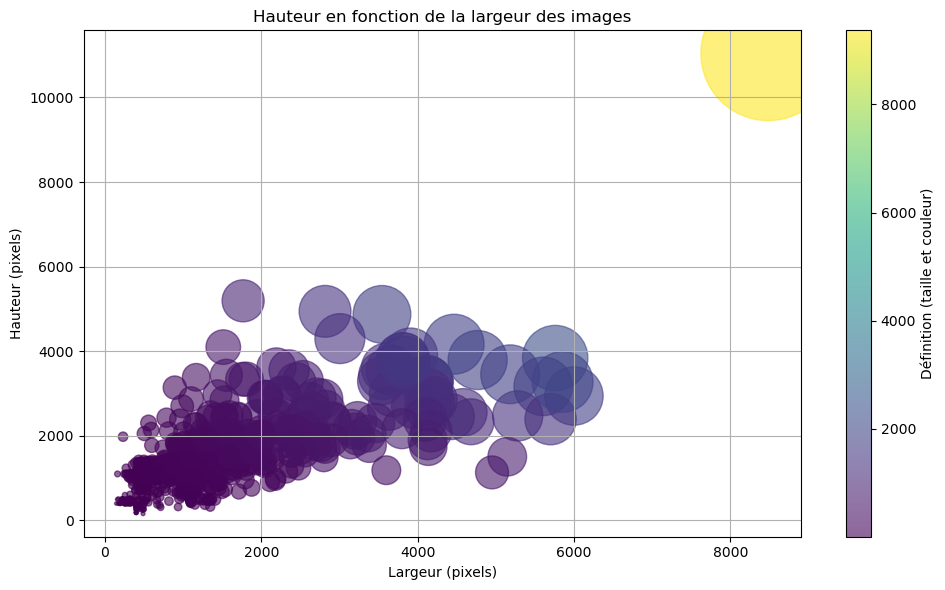

In [6]:
# Initialisation du graphique
plt.figure(figsize=(10, 6))

# Construction du scatterplot
sc =plt.scatter(
    Data_image['width'], 
    Data_image['height'],
    s=Data_image['definition'] / 10000, 
    alpha=0.6,
    c=Data_image['definition'] / 10000
)

# Ajout d'un titre
plt.title("Hauteur en fonction de la largeur des images")

# Ajout d'un titre sur l'axe des x
plt.xlabel("Largeur (pixels)")

# Ajout d'un titre sur l'axe des y
plt.ylabel("Hauteur (pixels)")

# Ajout d'une grille
plt.grid(True)

# Ajout d'une colorbar pour légender la  couleur
cbar = plt.colorbar(sc)
cbar.set_label('Définition (taille et couleur)')

# Ajustement du graphique
plt.tight_layout()

# Affichage du graphique
plt.show()

L'analyse du graphique représentant la hauteur en pixel en fonction de la largeur en pixel indique que les images ont des tailles très variables au sein du jeu de données. On repère également une image avec une taille particulièrement élevée qui correspond probablement à l'image à l'origine du message d'avertissement. 

De manière générale, il est recommandé de travailler avec des images de dimensions uniformes. Par conséquent, toutes les images seront redimensionnées à une taille standard de 224 pixels sur 224 pixels. 

In [7]:
def redimensionnement_image(images_data, image_size=(224, 224)):
    
    """
    Redimensionne une liste d'images à une taille donnée.

    Paramètres
        images_data (list of PIL.Image.Image) : Liste d'objets PIL représentant les images à redimensionner.
        image_size (tuple of int) : Taille cible pour le redimensionnement sous la forme (largeur, hauteur).

    Sortie
        Liste des images redimensionnées à la taille spécifiée.

    """
    
    # Initialisation de la liste d'image redimensionnée
    images_resized = []
    
    # Pour chaque images
    for img in images_data:
        
        # Redimension de l'image
        resized_img = img.resize(image_size)
        
        # Ajout de l'image redimensionnée dans la liste
        images_resized.append(resized_img)
        
    return images_resized

In [8]:
# Appel de la fonction de redimensionnement
Data_image['image_224x224'] = redimensionnement_image(Data_image['image'], image_size=(224, 224))

# Sauvegarde de la table avec les images brutes et prétraitées
Data_image.to_csv('../Output/Table/Data_image.csv')

# Affichage des 5 premières lignes de la dataframe
Data_image.head()

,image_path,uniq_id,label,First_category,image,width,height,definition,image_224x224
0,../Data\Images\55b85ea15a1536d46b7190ad6fff8ce...,55b85ea15a1536d46b7190ad6fff8ce7,4,Home Furnishing,<PIL.JpegImagePlugin.JpegImageFile image mode=...,3600,3600,12960000,<PIL.Image.Image image mode=RGB size=224x224 a...
1,../Data\Images\7b72c92c2f6c40268628ec5f14c6d59...,7b72c92c2f6c40268628ec5f14c6d590,0,Baby Care,<PIL.JpegImagePlugin.JpegImageFile image mode=...,2388,1293,3087684,<PIL.Image.Image image mode=RGB size=224x224 a...
2,../Data\Images\64d5d4a258243731dc7bbb1eef49ad7...,64d5d4a258243731dc7bbb1eef49ad74,0,Baby Care,<PIL.JpegImagePlugin.JpegImageFile image mode=...,982,729,715878,<PIL.Image.Image image mode=RGB size=224x224 a...
3,../Data\Images\d4684dcdc759dd9cdf41504698d737d...,d4684dcdc759dd9cdf41504698d737d8,4,Home Furnishing,<PIL.JpegImagePlugin.JpegImageFile image mode=...,1100,831,914100,<PIL.Image.Image image mode=RGB size=224x224 a...
4,../Data\Images\6325b6870c54cd47be6ebfbffa620ec...,6325b6870c54cd47be6ebfbffa620ec7,4,Home Furnishing,<PIL.JpegImagePlugin.JpegImageFile image mode=...,2670,2088,5574960,<PIL.Image.Image image mode=RGB size=224x224 a...


Avant de démarrer la phase de prétraitement des images, une autre fonction sera définie afin de visualiser quelques exemples d’images par catégorie. Cette première étape permettra non seulement d’avoir une première idée de la qualité des images contenues dans le jeu de données, mais aussi de vérifier la cohérence et la pertinence des labels attribués à chaque catégorie sur un échantillon des données.

## Visualisation d'images par catégorie

In [9]:
def plot_images_par_categories(df_images, image_col, category_col='category', n_images=3):
    
    """
    Affiche un échantillon d'images pour chaque catégorie présente dans un DataFrame.

    Paramètres
        df_images (pandas.DataFrame): Dataframe contenant les images et leurs catégories.
        image_col (str) : Nom de la colonne contenant les objets images.
        category_col (str, optionnel): Nom de la colonne contenant les catégories. 
        n_images (int, optionnel):Nombre d'images à afficher par catégorie.

    """
    
    # Création d'une lsite contenant les catégories par ordre alphabétique
    categories = sorted(df_images[category_col].dropna().unique())
    
    # Pour chaque catégorie
    for cat in categories:
        
        # Affichage de la catégorie
        print(f"Catégorie : {cat}")
        
        # Filtre des lignes pour cette catégorie et selection aléatoire de n_images
        images_cat = df_images[df_images[category_col] == cat].sample(n_images)
        
        # Construction du graphique
        fig, axs = plt.subplots(1, n_images, figsize=(9, 9))

        # Pour chaque images selectionnées
        for i, (_, row) in enumerate(images_cat.iterrows()):
            
            # Affichage de l'image
            axs[i].imshow(row[image_col])
            
            # Supression des axes
            axs[i].axis('off')
            
            # Ajout d'un titre
            axs[i].set_title(f'ID: {row["uniq_id"]}', size=9)
        
        # Ajustement du graphique
        plt.tight_layout()
        
        # Affichage du graphique
        plt.show()


Catégorie : Baby Care


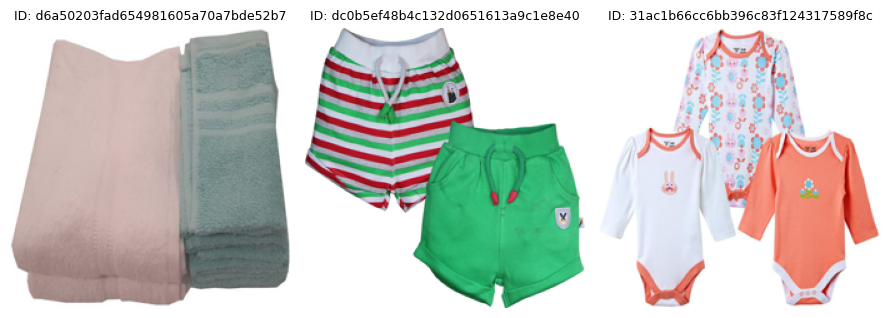

Catégorie : Beauty and Personal Care


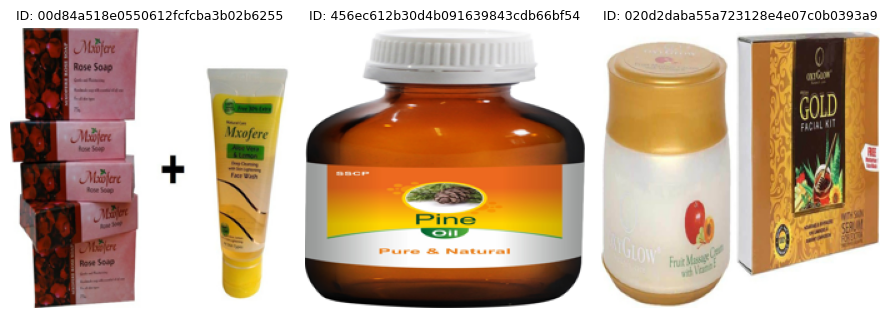

Catégorie : Computers


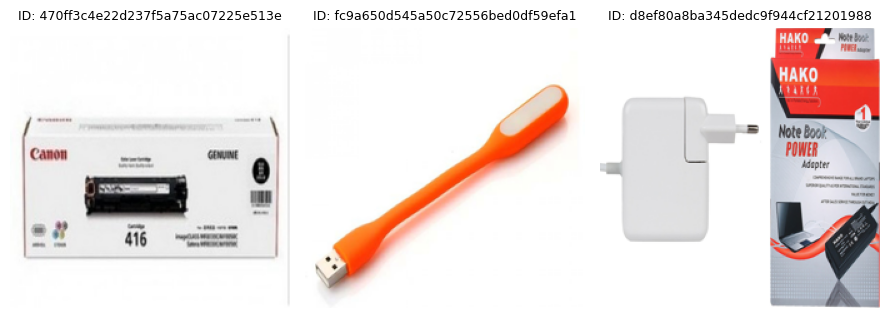

Catégorie : Home Decor & Festive Needs


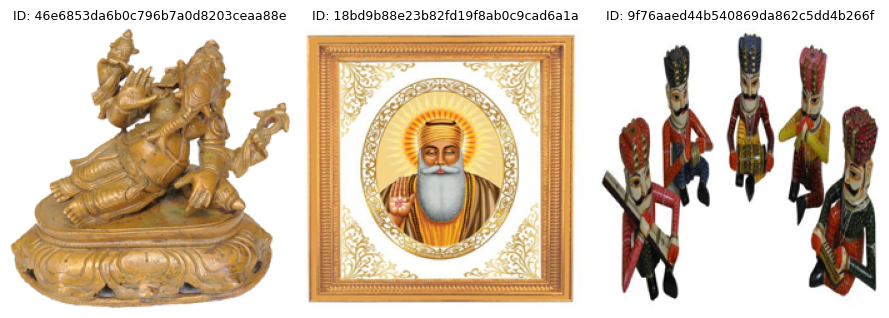

Catégorie : Home Furnishing


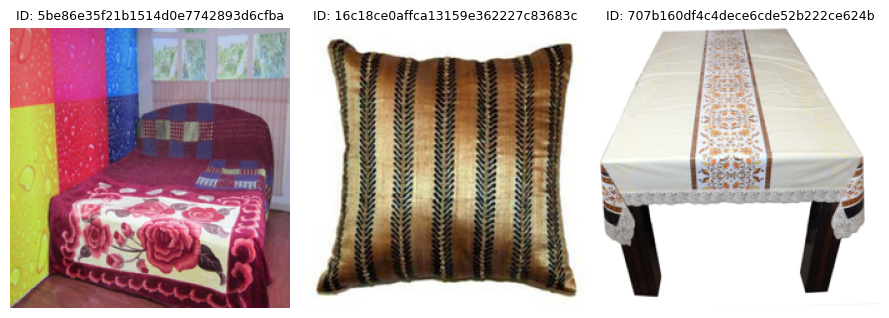

Catégorie : Kitchen & Dining


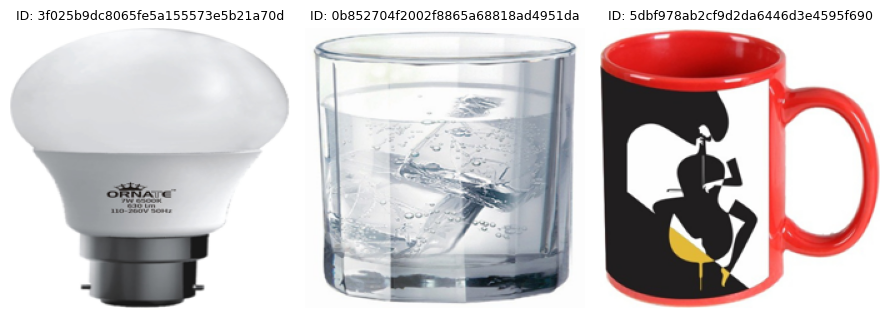

Catégorie : Watches


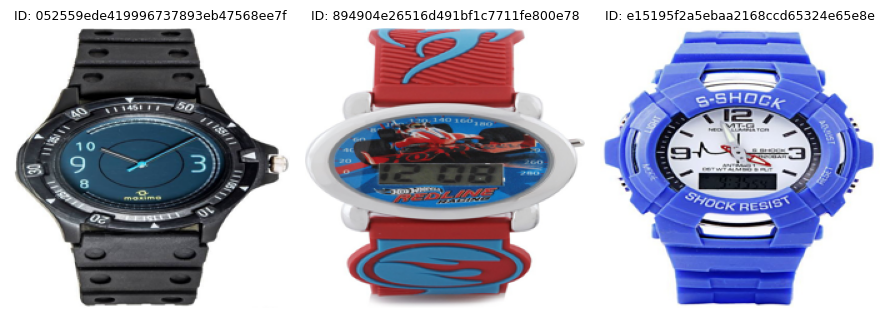

In [10]:
# Augmentention de la talle de la fenêtre d'affichage
display(HTML("<style>.output_scroll {height:auto !important; max-height: none !important;}</style>"))


# Supposons que df_images contient une colonne 'image' avec des objets PIL et une colonne 'category'
plot_images_par_categories(Data_image, image_col='image_224x224', category_col='First_category', n_images=3)


La visualisation de quelques exemples indique que les étiquettes de catégories aparaissent cohérentes avec le contenu des images. Ces dernières ne présentent pas de signes évidents de surexposition ou de sous exposition, et le contraste paraît satisfaisant mais ces observations reposent uniquement sur un échantillon restreint. Il ne semble pas non plus y avoir de bruit. On remarque toutefois une disparité dans les arrière plans des images : la majorité des images possèdent un fond blanc, tandis que certaines n’en ont pas. Cette hétérogénéité pourrait avoir un impact sur les performances des modèles d’apprentissage, notamment si le modèle apprend à exploiter le fond comme un indice de classification. Cela ne sera pas fait dans ce projet, mais il pourrait être pertinent d’uniformiser l’apparence des images, par exemple en supprimant ou en ajoutant un fond blanc, afin de limiter les biais liés à l’arrière plan et d’assurer une meilleure généralisation du modèle.

# Prétraitement des images

Dans cette partie, différentes étapes de prétraitement d'image seront analysées sur un exemple d'image. Elles seront ajoutées au fur et a mesure à l'aide d'une fonction qui pourra prendre en entrée soit une image et retourner l'image transformée, soit une dataframe contenant des images et retourner une liste des images modifiées avec les transformations appliquées. L'impact de chacune des étapes de prétraitement sera analysée grâce à l'étude de l'histogramme associé aux images qui sera construit à l'aide d'une deuxième fonction. Un histogramme d'une image est une représentation graphique de la distribution des intensités des pixels dans une image. Pour une image en niveau de gris, il indique combien de pixel possèdent une intensité donnée allant du noir au blanc. Dans le cas d'une image en couleur l'histogramme peut être calculé séparément pour chaque canal RGB.

Parmis les étapes de prétraitement classiquement utilisées en traitement d'images il y a: 
- la conversion en niveaux de gris, qui permet de simplifier l’image en supprimant la dimension couleur tout en conservant l’information de luminosité
- l’égalisation de l’histogramme, qui permet de redistribuer les intensités pour améliorer le contraste global de l'image
- l’étirement de l’histogramme, qui vise à corriger la luminosité de l'image.
- le filtrage du bruit qui permet de réduire les variations non souhaitées (bruit de fond, artefacts).

## Analyse sur un exemple

In [11]:
def process_images(data, 
                   image_col=None, 
                   en_gris=True, 
                   filtrage_bruit=False, 
                   egalisation_histo=False, 
                   etirement_histo=False,
                   verbose=True):
    """
    Applique des traitements à une image PIL ou une colonne d'images dans un DataFrame.

    Paramètres:
        data (PIL.Image.Image ou pd.DataFrame): image unique ou DataFrame contenant des images.
        image_col (str, optionnel): nom de la colonne d'images si DataFrame.
        en_gris (bool): converti ou non en niveaux de gris.
        filtrage_bruit (bool): applique ou non un filtre gaussien.
        egalisation_histo (bool): applique ou non une égalisation d'histogramme.
        etirement_histo (bool): applique ou non un étirement d'histogramme.
        verbose (bool): affiche ou non des informations

    Sortie:
        Image seule si entrée image, ou liste d'images si entrée DataFrame.
    """

    # Mode image seule
    single_image_mode = False
    
    # Si l'entrée est une image, conversion de l'entrée en dataframe
    if isinstance(data, Image.Image):
        data = pd.DataFrame({'_img': [data]})
        image_col = '_img'
        single_image_mode = True

    # Initialisation d'une liste stockant les résultats
    images_processed = []
    
    # Pour chaque image
    for img in data[image_col]:
        
        # Conversion en gris
        img_processed = img.convert("L") if en_gris else img.copy()

        # Egalisation de l'histogramme
        img_processed = ImageOps.equalize(img_processed) if egalisation_histo else img_processed

        # Etirement de l'histogramme
        if etirement_histo:
            
            # Conversion de l'image en array
            arr = np.array(img_processed).astype(np.float32)
            
            # Si verbose = True
            if verbose :
                
                # Calcul des valeurs min et max de l'intensité des pixels
                min_val, max_val = arr.min(), arr.max()
                
                # Affichage des valeurs min et max
                print(f"Min avant étirement : {min_val}, Max : {max_val}")
            
            # Etirement de l'histogramme 
            arr = 255 * (arr - arr.min()) / (arr.max() - arr.min() + 1e-5)
            
            # Conversion de l'array en image
            img_processed = Image.fromarray(arr.astype(np.uint8))

        # Filte du bruit
        img_processed = img_processed.filter(ImageFilter.MedianFilter(size=3)) if filtrage_bruit else img_processed

        # Ajout de l'image prétraitée dans la liste
        images_processed.append(img_processed)

    # Sortie selon l'entrée
    if single_image_mode:
        return images_processed[0]
    else:
        return images_processed


In [12]:
def plot_image_histo(image, titre=None,lastbin=256):
    """
    Affiche une image (PIL ou numpy array) et son histogramme.
    Gère les images en niveaux de gris et en couleur (RGB).

    Paramètres:
        image (PIL.Image.Image ou np.ndarray): image à afficher.
        titre (str, optionnel): titre à afficher.
        lastbin (int): nombre de bins pour l'histogramme (par défaut 256).
    """

    # Conversion en numpy array si image PIL
    if hasattr(image, 'resize'):
        img_array = np.array(image)
    elif isinstance(image, np.ndarray):
        img_array = image
    else:
        raise TypeError(f"Type d'image inattendu : {type(image)}")


    # Détection image couleur ou niveau de gris
    is_color = (img_array.ndim == 3 and img_array.shape[2] == 3)

    # Si l'image est en couleur
    if is_color:
        
        # Construction de la figure avec l'image + 3 histogrammes
        fig, axs = plt.subplots(1, 4, figsize=(16, 4), gridspec_kw={'width_ratios': [2.5, 1, 1, 1]})

        # Affichage de l'image couleur
        axs[0].imshow(img_array)
        axs[0].set_title(titre)
        axs[0].axis('off')

        # Définition d'une liste avec les trois couleurs
        colors = ['r', 'g', 'b']
        
        # Construction des trois histogrammes
        for i, color in enumerate(colors):
            axs[i+1].hist(img_array[:, :, i].flatten(), bins=range(lastbin), color=color, alpha=0.7)
            axs[i+1].set_title(f"Histogramme canal {color.upper()}")
            axs[i+1].set_xlabel("Intensité (0-255)")
            axs[i+1].set_ylabel("Nombre de pixels")
            axs[i+1].grid(True)

    else:
        # Construction de la figure avec l'image + 1 histogramme
        fig, axs = plt.subplots(1, 2, figsize=(10, 4))
        
        # Affichage de l'image en gris
        axs[0].imshow(img_array, cmap='gray')
        axs[0].set_title(titre)
        axs[0].axis('off')
        
        # Construction de l'histogramme
        axs[1].hist(img_array.flatten(), bins=range(lastbin), color='gray')
        axs[1].set_title("Histogramme des intensités")
        axs[1].set_xlabel("Intensité (0-255)")
        axs[1].set_ylabel("Nombre de pixels")
        axs[1].grid(True)

    # Ajustement de la figure
    plt.tight_layout()
    
    # Sauvegarde de la figure
    plt.savefig(f'../Output/Preprocessing_images/Histogramme des intensités ({titre}).png', format='png')

    # Affichage de la figure
    plt.show()


In [13]:
# Choix de l'image à utiliser comme exemple
ex_id = "998a39dca0ef610c3a0ea4e9cc6e1681"

# Filtre de la dataframe pour cet uniq_id
df_image_ex = Data_image[Data_image['uniq_id'] == ex_id]

# Extraction de l'image
image = df_image_ex['image'].iloc[0]

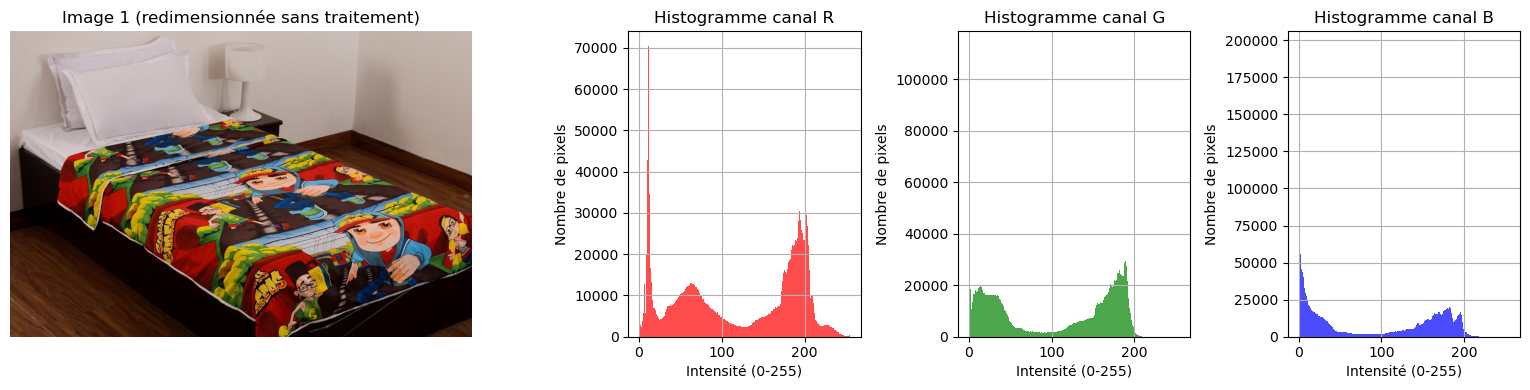

In [14]:
# Affichage de l'image et de l'histogramme associé
plot_image_histo(image, titre = 'Image 1 (redimensionnée sans traitement)')

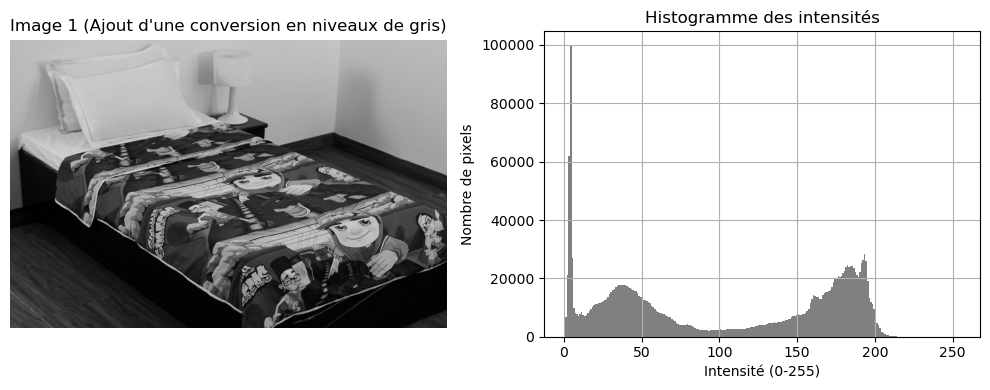

In [15]:
# Conversion de l'image en niveau de gris
img_processed_1 = process_images(image, 
                   image_col=None, 
                   en_gris=True, 
                   filtrage_bruit=False, 
                   egalisation_histo=False, 
                   etirement_histo=False)

# Affichage de l'image et de l'histogramme associé
plot_image_histo(img_processed_1, titre ="Image 1 (Ajout d'une conversion en niveaux de gris)")

Cette figure permet de visualiser l'image ainsi que l'histogramme correspondant avant les différentes étapes de prétraitement afin d'évaluer visuellement leur impact. On remarque le les niveaux de gris sont compris entre 0 et 210 environs. Dans un premier temps on va essayer d'étirer l'histogramme afin de répartir les intensités sur l’ensemble de la plage (de 0 à 255), dans le but d’améliorer la luminosité.

Min avant étirement : 0.0, Max : 253.0


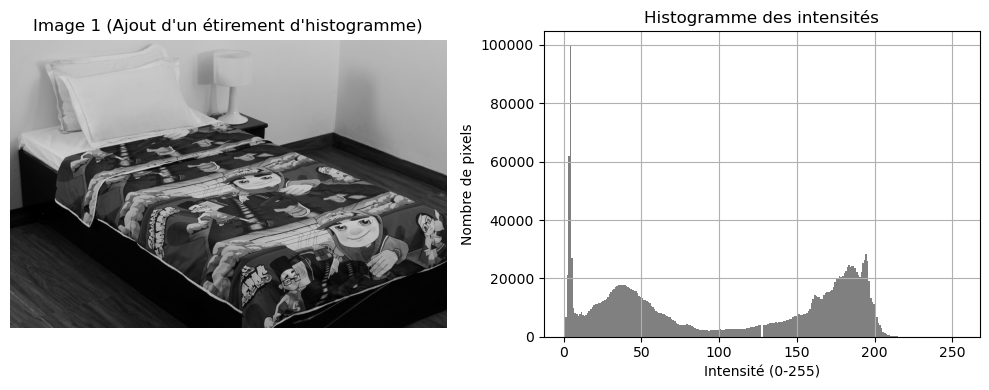

In [16]:
# Ajout d'une étape d'égalisation
img_processed_2 = process_images(image, 
                   image_col=None, 
                   en_gris=True, 
                   filtrage_bruit=False, 
                   egalisation_histo=False, 
                   etirement_histo=True)

# Affichage de l'image et de l'histogramme associé 
plot_image_histo(img_processed_2, titre = "Image 1 (Ajout d'un étirement d'histogramme)")

Lorsqu'on applique un étirement d'histogramme à cette image on n'observe pas de modification sur l'histogramme correspondant à l'image modifée. Cela peut s'expliquer par le fait que la valeur maximal atteignait déjà en réalité 253 avant étirement. Cette valeur élevée n’était pas clairement visible sur l’histogramme initial, probablement en raison d’un nombre très limité de pixels concernés. On essaiera d'analyser l'impact de ce traitement sur une autre image. 

Concernant l'image actuelle, on va maintenant ajouter une étape permettant d'égaliser l'histogramme de manière à obtenir une redistribution plus uniforme des niveaux de gris, dans le but d’améliorer le contraste global de l'image.

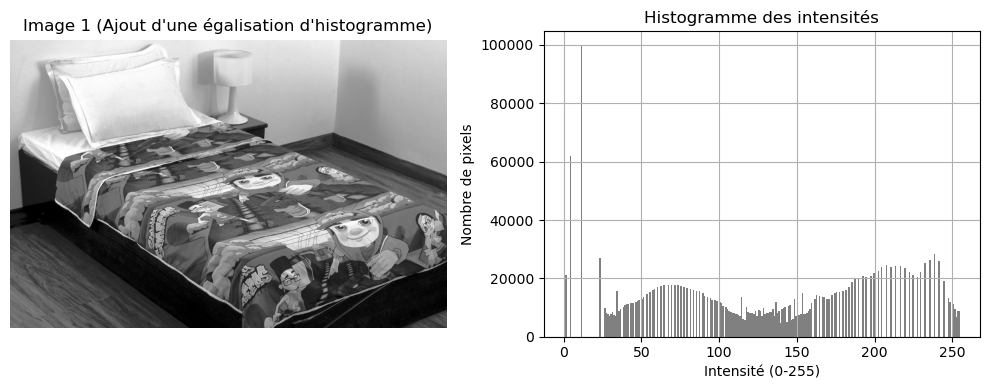

In [17]:
# Ajout d'une étape d'étirement d'histogramme
img_processed_3 = process_images(image, 
                   image_col=None, 
                   en_gris=True, 
                   filtrage_bruit=False, 
                   egalisation_histo=True, 
                   etirement_histo=False)

# Affichage de l'image et de l'histogramme associé 
plot_image_histo(img_processed_3, titre = "Image 1 (Ajout d'une égalisation d'histogramme)")

Lorsqu'on applique une étape d'égalisation d'histogramme, on remarque que les niveau de gris sont plus uniformes. Les pics identifiables sur l'histogramme de l'image avant cette étape de pré traintement ont été atténués ce qui conduit à une répartition plus homogène des niveaux de gris. On observe que cet effet est également visible directement sur l'image. 

Il serait également possible d'analyse l'impact de l'ajout d'un filtre pour réduire le bruit de l'image. Néanmoins cette image tout comme les autres images inclues dans le jeu de données ne semblent pas contenir de bruit. On l'appliquera tout de même par précaution.

Pour évaluer l'impact de l'étape d'étirement d'historamme on va utiliser une autre image dont la lumosité est plus faible. 

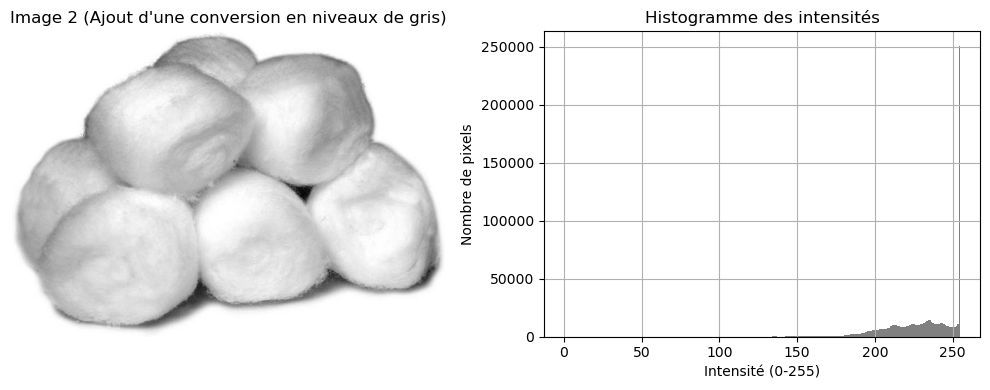

In [18]:
# Choix de l'image à utiliser comme exemple
ex_id_2 = "11f06dffebf7edf9e15351834a190c2c"

# Filtre de la dataframe pour cet uniq_id
df_image_ex_2 = Data_image[Data_image['uniq_id'] == ex_id_2]

# Extraction de l'image
image_ex_2 = df_image_ex_2['image'].iloc[0]

# Conversion de l'image en niveau de gris
img_processed_5 = process_images(image_ex_2, 
                   image_col=None, 
                   en_gris=True, 
                   filtrage_bruit=False, 
                   egalisation_histo=False, 
                   etirement_histo=False)

# Affichage de l'image et de l'histogramme associé
plot_image_histo(img_processed_5, titre ="Image 2 (Ajout d'une conversion en niveaux de gris)")

Lorsqu'on analyse l'histogramme associé a cette image, on remarque que les pixels se concentrent dans la partie droite de l'histogramme ce qui confirme la sous exposition de cette image. Pour corriger cela, on va ajouter une étape d'étirement d'histogramme. Cela permettra de répartir les niveaux de gris sur la totalité de la plage de l'histogramme.

Min avant étirement : 100.0, Max : 255.0


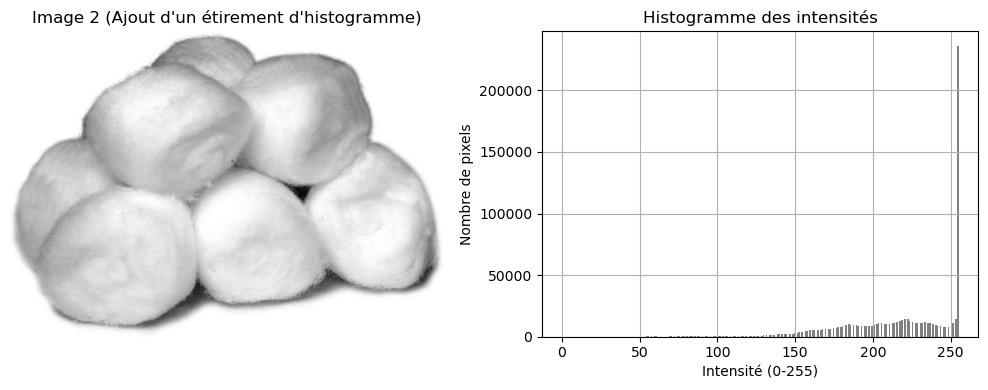

In [19]:
#  Ajout d'une étape d'étirement d'histogramme
img_processed_5 = process_images(image_ex_2, 
                   image_col=None, 
                   en_gris=True, 
                   filtrage_bruit=False, 
                   egalisation_histo=False, 
                   etirement_histo=True)

# Affichage de l'image et de l'histogramme associé
plot_image_histo(img_processed_5, titre ="Image 2 (Ajout d'un étirement d'histogramme)")

Lors quq'on étire l'histogramme de cette image sous exposée, on remarque que les niveau de gris apparaissent un peu plus étalés vers la gauche de l'histogramme.

# Extraction de features

L’extraction de caractéristiques dans les images peut se faire selon plusleiurs approches dont la complexité varie. Les méthodes traditionnelles, comme SIFT, SURF et ORB, détectent des points clés et calculent des descripteurs pour représenter localement l’image.  Il existe également des méthodes plus avancées basées sur des réseaux de neurones qui extraient de façon automatique des représentations visuelles plus riches à partir d'un CNN ou d'un transformer. Chacune de ces méthodes seront explicitées lorsqu'elles seront appliquées.

Les deux premières méthodes, SIFT et ORB, permettent d'extraire des descripteurs locaux à partir des images. Cependant, un nombre variable de descripteur peut être identifés dans les images. Ces descripteurs ne constituent donc pas directement les caractéristiques finales exploitables pour l’analyse. Par exemple, avec ORB, les descripteurs extraits pour chaque image sont des tableaux NumPy de taille variable (n, 32) où n représente le nombre de points clés détectés dans l’image, et chaque descripteur est un vecteur de dimension 32 décrivant localement une zone spécifique de l’image.

Pour obtenir des vecteurs de caractéristiques de taille fixe, utilisables dans les modèles de machine learning, une étape de transformation est nécessaire. Tous les descripteurs extraits de l'ensemble des images sont d'abord regroupés, puis un algorithme de clustering tel que KMeans est appliqué afin de regrouper les descripteurs similaires. Chaque cluster formé représente alors un mot visuel, c’est à dire une sorte de motif moyen.

L'étape suivante consistera à construire, pour chaque image, un Bag of Visual Words (BoVW) comparable au Bag of Words utilisé lors de la partie sur le traitement des données textuelles. Pour cela, les descripteurs de chaque image seront affectés aux clusters obtenus. On constuit alors pour chaque image un histogramme qui indique combien de descripteurs identifés dans l'image ont été associés à chaque cluster. Cet histogramme est ensuite normalisé, afin de le rendre indépendant du nombre de descripteurs extraits dans l’image. On obtient ainsi, pour chaque image, un vecteur de caractéristiques de taille fixe, dont la dimension est égale au nombre de clusters. Chaque composante du vecteur représente la fréquence d’apparition d’un type particulier de motif visuel dans l’image.

Quelle que soit la méthode utilisée pour l’extraction des caractéristiques (ORB, SIFT, descripteurs issus d’un CNN), les vecteurs obtenus seront projetés sur un espace à deux dimensions à l’aide d’un t-SNE pour visualiser la structure des données. Afin de réduire le temps de calcul et d'améliorer la séparation des groupes dans l’espace réduit, une PCA sera appliquée en amont pour diminuer la dimensionnalité initiale tout en conservant l’information la plus pertinente (pour conserver un maximum de la variance des données, le paramètre n component de la PCA sera fixé à 0.99). Cette étape permettra de voir si les produits d'une même catégorie ont tendance à se regrouper ensemble dans cet espace réduit. Un second clustering pourra être appliqué sur les vecteurs réduits pour calculer un score ARI indiquant dans quelle mesure les clusters retrouvés correspondent aux catégories réelles des produits.

## Définition de fonctions utiles

Pour mettre en place tout ce qui vient d'être expliqué, quatres nouvelles fonctions vont être définies:
- la première fonction permettra d'extraire les descripteurs par images selon la méthode SIFT ou ORB
- la deuxième fonction permettra d'appliquer la premère segmentation visant à obtenir les visual word moyens
- la troisième fonction permettra de construire les vecteurs de caractéristiques correspondant aux BoVW
- la dernière fonction permettra de projeter les vecteurs dans un espace en deux dimensions et de calculer le score ARI

In [20]:
def extract_descriptors(images, method='SIFT', nfeatures=500, verbose=True, show_hist=True):
    """
    Extrait les descripteurs (SIFT, ORB) pour une liste ou une colonne d'images PIL en niveaux de gris.
    Affiche un histogramme représentant le nombre de descripteurs par image.
    
    Paramètres:
        images (list ou pd.Series): liste ou colonne pandas contenant des images PIL en niveaux de gris.
        method (str): 'SIFT'ou 'ORB'.
        nfeatures (int): nombre max de points clés à identifier.
        verbose (bool): affichage ou non de la progression.
    
    Sortie:
        tuple: (liste des descripteurs par image, np.array concaténé de tous les descripteurs)
    """
    
    
    # Initialisation de l'extracteur selon la méthode SIFT ou ORB
    if method == 'SIFT':
        detector = cv2.SIFT_create(nfeatures=nfeatures)
    elif method == 'ORB':
        detector = cv2.ORB_create(nfeatures=nfeatures)
    else:
        raise ValueError(f"Méthode inconnue : {method}")

    # Initialisation de la liste de descripteurs par image
    descriptors_list = []
    
    # Calcul du temps avant le début de l'extraction des descripteurs
    start_time = time.time()

    # Pour chaque images
    for i, pil_img in enumerate(images):
        
        # Si demandé, affichage de la progression
        if verbose and i % 500 == 0:
            print(f"Traitement image {i}/{len(images)}")
        
        # Conversion de l'image en array
        img_np = np.array(pil_img)  

        # Obtention des descripteurs
        kp, des = detector.detectAndCompute(img_np, None)
        
        # Ajout des descripteurs dans la liste
        descriptors_list.append(des)

    # Extraction des descripteurs non nuls
    descriptors_non_none = [d for d in descriptors_list if d is not None]
    
    # Si la liste n'est pas nulle, on les concatène dans une array
    if len(descriptors_non_none) > 0:
        all_descriptors = np.concatenate(descriptors_non_none, axis=0)
    
    # Sinon, on consuit une array vide
    else:
        all_descriptors = np.array([])

    # Calcul du temps d'execution de l'extraction de features
    duration = time.time() - start_time
    
    # Affichage du nombre de descripteurs identifiés et du temps d'execution
    print(f"\nNombre total de descripteurs : {all_descriptors.shape if all_descriptors.size > 0 else all_descriptors}")
    print(f"Temps d'extraction ({method}) : {duration:.2f} secondes")
    
    # Calcul du nombre de descripteurs par image
    nb_descripteurs_par_image = [0 if d is None else len(d) for d in descriptors_list]
    
    # Construction de la figure
    if show_hist:
        plt.figure(figsize=(12, 4))    
        plt.hist(nb_descripteurs_par_image, bins=50)
        plt.xlabel("Nombre de descripteurs par image")
        plt.ylabel("Fréquence")
        plt.savefig(f'../Output/Extraction_de_features_images/Distribution des descripteurs SIFT.png', format='png')
        plt.title("Distribution des descripteurs SIFT")
        
        plt.show()
    return descriptors_list, all_descriptors


In [21]:
def train_kmeans(all_descriptors, n_clusters='auto', verbose=True):
    """
    Entraîne un modèle KMeans sur tous les descripteurs.

    Paramètres:
        all_descriptors (np.array): concaténation de tous les descripteurs.
        n_clusters (int ou 'auto'): nombre de clusters. Si 'auto', calcul via la formule sqrt(nb_descripteurs).
        verbose (bool): affichage ou non d'informations.

    Sortie:
        kmeans: modèle MiniBatchKMeans entraîné.
    """
    
    # Définition du temps avant l'execution du code de la fonction
    start=time.time()
    
    # Test de la taille des descipteur
    if all_descriptors.size == 0:
        if verbose:
            print("Pas de descripteurs à clusteriser.")
        return None
    
    # Si auto, calcul du nombre de cluster
    if n_clusters == 'auto':
        n_clusters = int(round(np.sqrt(len(all_descriptors))))
        
    # Affichage du nombre de cluster
    if verbose:
        print(f"Nombre de clusters utilisé : {n_clusters}")
           
    # Initialisation du modèle de clustering
    kmeans = MiniBatchKMeans(n_clusters=n_clusters, init_size=3*n_clusters, random_state=0)

    # Entrainement du modèle de clustering sur tous les descripteurs
    kmeans.fit(all_descriptors)
    
    # Calcul du temps d'execution du code de la fonction
    duration = time.time() - start
    
    # Affichage du temps d'execution du code
    if verbose:
        print('temps de traitement du Kmeans:', "%15.2f" %  duration, "secondes")

    return kmeans


In [22]:
def build_histograms(kmeans, descriptors_list, verbose=True, show_examples=True):
    """
    Pour chaque image, construit un histogramme des clusters d'appartenance des descripteurs.
    Affichage de quelques un de ces histogrammes.

    Paramètres:
        kmeans: modèle MiniBatchKMeans entraîné.
        descriptors_list (list de np.array): liste des descripteurs par image.
        verbose (bool): affichage ou non des infos.
        show_examples (bool): affichage ou non d'examples d'hisgrammes.

    Sortie:
        np.array: matrice des histogrammes (une ligne par image, une colonne par cluster).
    """

    # Extraction du nombre de cluster de la segmentation (= dimension du vecteur de sortie)
    n_clusters = kmeans.n_clusters
    
    # Initialisation de la liste qui stockera les vecteurs de chaque image
    hist_vectors = []

    # Pour chaque image
    for i, des in enumerate(descriptors_list):
        
        # Si l'image a au moins un descripteur
        if des is not None and len(des) > 0:
            
            # prédiction des clusters de chaque descripteur
            labels = kmeans.predict(des)
            
            # Initialisation d'un vecteur correspondant à l'histogramme des visual words
            hist = np.zeros(n_clusters)
            
            # Cacul du nombre de descripteurs detectés dans une image
            nb_des = len(des)
            
            # Ajout de la fréquence d'apparaition des descripteurs et normalisation du vecteur 
            for label in labels:
                hist[label] += 1.0 / nb_des
                
            # Ajout du vecteur dans la liste de résultats
            hist_vectors.append(hist)
            
            # Affichage de l'histogramme de la première image
            if show_examples and i == 0:
                plt.figure(figsize=(8, 3))
                plt.bar(range(n_clusters), hist)
                plt.title(f"Histogramme des visual words – Image {i}")
                plt.xlabel("Cluster (mot visuel)")
                plt.ylabel("Fréquence normalisée")
                plt.grid(True)
                plt.tight_layout()
                plt.savefig(f'../Output/Extraction_de_features_images/Histogramme.png', format='png')
                plt.show()
        
        # Si l'image n'a pas de descripteurs, le vecteur de sortie sera nul
        else:
            hist_vectors.append(np.zeros(n_clusters))

    return np.asarray(hist_vectors)


In [23]:
def clustering_and_evaluation(feature, df, method, n_clusters=7, verbose=False, title="Evaluation clustering"):
    
    """
    Évalue la qualité d’un clustering par KMeans sur des données réduites par PCA et t-SNE, 
    puis affiche les résultats avec une visualisation 2D et calcule le score ARI.

    Paramètres
        feature (array-like of shape (n_samples, n_features)): Matrice de caractéristiques à évaluer.
        df (pandas.DataFrame) : DataFrame contenant la colonne avec les catégories réelles des produits.
        method (str): Nom de la méthode ou du modèle utilisé pour extraire les features.
        n_clusters (int): Nombre de clusters à utiliser pour le clustering KMeans.
        verbose (bool): Affichage ou non d'informations 
        title (str): Titre général de la figure affichée.
    """
        
    # Réduction de dimension par PCA
    pca = PCA(n_components=0.99, random_state=42)
    feat_pca = pca.fit_transform(feature)
    
    # Si demandé affichage du nombre de dimension avant et après la PCA
    if verbose:
        print("Dimensions avant PCA :", feature.shape)
        print("Dimensions après PCA :", feat_pca.shape)
    
    # Réduction de dimension par TSNE
    tsne = TSNE(n_components=2, perplexity=30, max_iter=2000, init='random', random_state=6)
    X_tsne = tsne.fit_transform(feat_pca)
    
    # Clustering sur les données du TSNE
    cls = KMeans(n_clusters=n_clusters, n_init=100, random_state=6)
    cls.fit(X_tsne)
    y_pred = cls.labels_
    
    # Calcul du score ARI
    y_true = df["First_category"]
    ari = adjusted_rand_score(y_true, y_pred)
    if verbose:
        print(f"Adjusted Rand Index (ARI) : {ari:.4f}")
    
    # Conversion en Dataframe
    df_tsne = pd.DataFrame(X_tsne, columns=["tsne1", "tsne2"])
    df_tsne["true_label"] = y_true
    df_tsne["cluster_label"] = y_pred.astype(str)  
    
    # Construction de la figure
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot 1: Vrais catégories
    sns_plot1 = sns.scatterplot(ax=axes[0], data=df_tsne, x="tsne1", y="tsne2", hue="true_label", palette="tab10", s=30, alpha=0.8)
    axes[0].set_title("True labels (t-SNE)")
    axes[0].set_xlabel("t-SNE 1")
    axes[0].set_ylabel("t-SNE 2")

    # Plot 2: Cluster du KMeans
    sns_plot2 = sns.scatterplot(ax=axes[1], data=df_tsne, x="tsne1", y="tsne2", hue="cluster_label", palette="tab10", s=30, alpha=0.8)
    axes[1].set_title("Cluster labels (t-SNE)")
    axes[1].set_xlabel("t-SNE 1")
    axes[1].set_ylabel("t-SNE 2")

    # Ajout d'un titre
    fig.suptitle(title)
    
    # Sauvegarde du graphique
    plt.savefig(f'../Output/Extraction_de_features_images/Evaluation_clustering_({method}).png', format='png')

    # Affichage du graphique
    plt.show()
    
    return ari


## Extraction de features avec la méthode SIFT

La méthode SIFT (scale invariant feature transform) vise à détecter dans une image des points d'intérêts ou points clés robustes aux transformations classiques telles que le changement d'échelle, la rotation, l'ajout de bruit.  Ces points clés sont ensuite caractérisés par des vecteurs descripteurs caractéristiques permettant de comparer les images entre elles. 

Pour consuitre les vecteurs, un zoom autour du point clé sera appliqué. La zone correspondante au zoom est ensuite découpées en petit bloc. Dans chaque bloc, on regarde pour chaque pixel dans quelle direction va l'intensité lumineuse. Par la suite un histogramme des directions des gradients mesurés à l'étape précédente est construit et apporte un résumé des orientations dominantes présentes dans le bloc en question. Les valeurs des histogramme de chaque bloc sont ensuite ajoutés les uns à la suite des autres pour former le vecteur descripteur du point clé.

### Exemple sur une image

Min avant étirement : 0.0, Max : 255.0


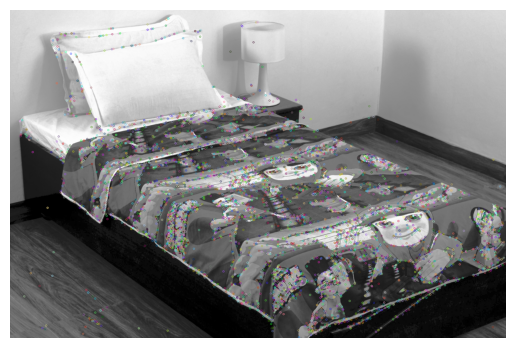

Descripteurs :  (5500, 128) 
 [[ 13.   4.   4. ...   1.   0.   0.]
 [  0. 151. 110. ...   0.   9.  16.]
 [  0. 155.  80. ...   2.  12.  18.]
 ...
 [  0.   2.   0. ...  33.   0.   0.]
 [ 12.   1.   0. ...  16.   4.   6.]
 [  3.   3.   2. ...   1.   0.   1.]]


In [24]:
# Image d'exemple prétraités avec les 4 étapes de prétraitement
image_ex = process_images(image, 
                   image_col=None, 
                   en_gris=True, 
                   filtrage_bruit=True, 
                   egalisation_histo=True, 
                   etirement_histo=True)

# Conversion en array
img_np = np.array(image_ex)

# Initialisation de l'extracteur
sift = cv2.SIFT_create()

# Application de l'extracteur pour obtenir les key points et les descripteurs
kp, des = sift.detectAndCompute(img_np, None)

# Ajout des key point sur l'image 
img=cv2.drawKeypoints(img_np,kp,img_np)

# Construction du plot pour visualiser l'image
plt.imshow(img,  cmap='gray')

# Suppression des axes
plt.axis('off')

# Affichage de l'image
plt.show()

# Affichage de la taille des descripteurs
print("Descripteurs : ", des.shape, "\n", des)

Sur l'image présentée en exemple,on peut repérer les nombreux points clés détectés par l’algorithme SIFT. On remarque que ces points clés sont majoritairement localisés au niveau de bords ou de contours. La taille de la matrice de descripteurs associée à ces points indique que 5500 points clés ont été identifiés dans l’image, chacun étant décrit par un vecteur de 128 valeurs. On peut mainteant appliquer cette technique à l'ensemble des images.

### Application sur l'ensemble des images

In [25]:
# Définition du temps de départ
start = time.time()

# Application des traitements aux images
Data_image.loc[:, 'image_process_SIFT'] = process_images(Data_image, 'image_224x224', 
                                                         en_gris=True,
                                                         filtrage_bruit=True,
                                                         egalisation_histo=True,
                                                         etirement_histo=True,
                                                         verbose=False)

Traitement image 0/1050
Traitement image 500/1050
Traitement image 1000/1050

Nombre total de descripteurs : (347868, 128)
Temps d'extraction (SIFT) : 15.95 secondes


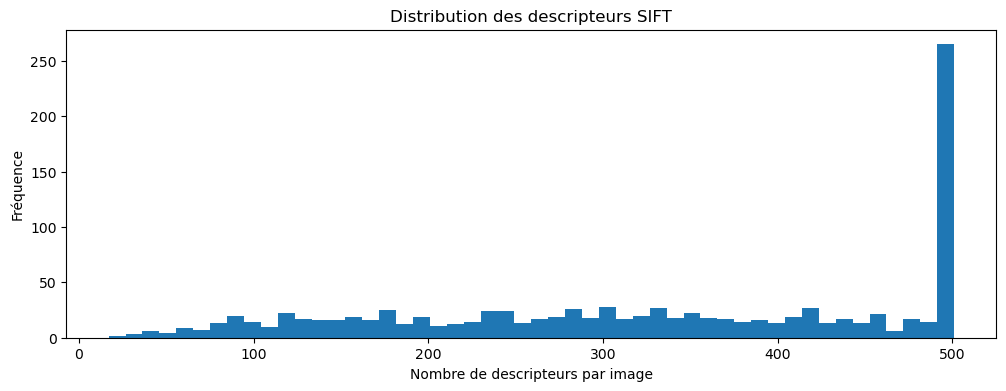

In [26]:
# Obtention des descripteurs
descs_list, all_descs = extract_descriptors(Data_image['image_process_SIFT'], method='SIFT')

La figure ci dessus représente la distribution du nombre de vecteurs descripteurs identfiés dans les images de notre jeu de données. La majorité des images ont été caractérisées par environs 500 descripteurs qui est la limite maximal fixée par la fonction d'extraction qui a été définie. 

L'ensemble des descripteurs extraits de toutes les images vont donc être rassemblés pour entrainer un KMeans de manière a identifier un nombre fixe de descripteurs moyens qui serviront de mots visuel qui seront utilisés pour la consutruction de l'histogramme correspondant au Bag of Visual Words pour chaque image.

Nombre de clusters utilisé : 590
temps de traitement du Kmeans:            4.15 secondes


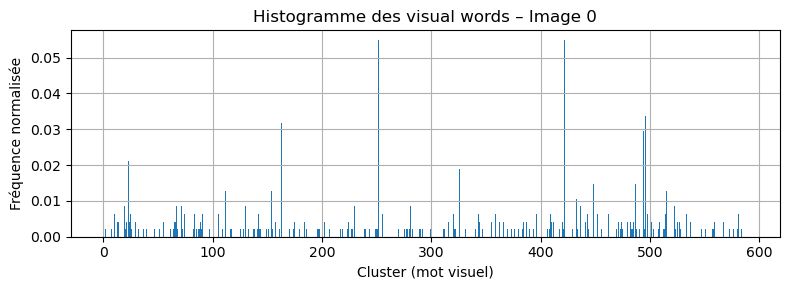

In [27]:
# Entrainement du Kmeans
kmeans_model = train_kmeans(all_descs, n_clusters='auto')

# Construction des features
im_features = build_histograms(kmeans_model, descs_list, verbose=True, show_examples=True)

# Calcul du temps d'extraction des features
duration_SIFT = time.time() - start

Cette figure représente un exemple d'histogramme de bag of visual word pour une image. Chaque barre de l'histogramme correspond a un mot visuel moyen c'est à dire à l’un des centroïdes identifiés lors de l’entraînement de l’algorithme du KMeans sur l’ensemble des descripteurs.
La hauteur des barres reflète alors la fréquence d’apparition des descripteurs de l’image qui ont été assignés à chacun de ces mots visuels après prédiction via le KMeans entrainé.

Dimensions avant PCA : (1050, 590)
Dimensions après PCA : (1050, 480)
Adjusted Rand Index (ARI) : 0.0366


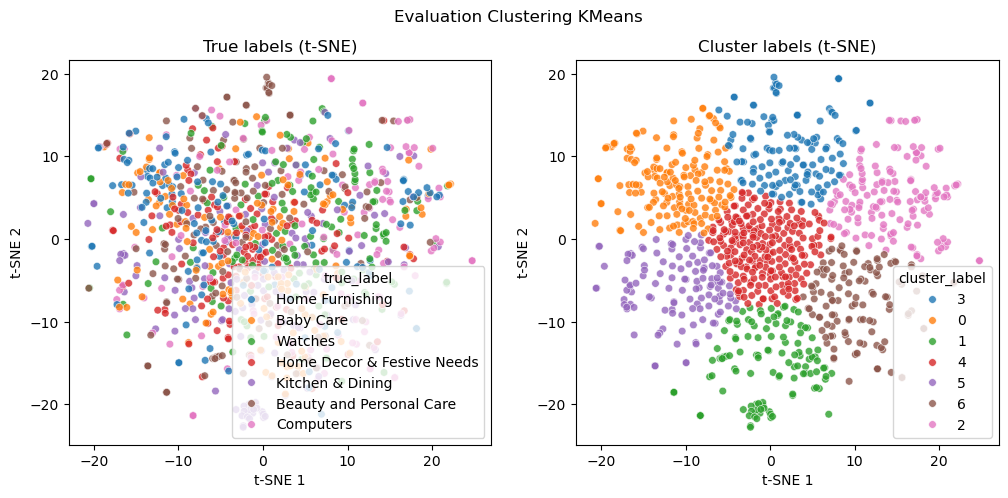

In [28]:
# Affichage des représentation 2D via TSNE avec catégorie réelles ou prédites
ari_SIFT = clustering_and_evaluation(im_features, Data_image, 'SIFT', n_clusters=7, verbose=True, title="Evaluation Clustering KMeans")

In [29]:
# Création de la dataframe de résultats
Resultats_SIFT = pd.DataFrame({
    'approche': ['SIFT'],
    'ari': [ari_SIFT],
    "temps d'execution": [duration_SIFT]
})

La projection en deux dimensions des features extraites grâce à la méthode SIFT ne met en évidence aucune séparation nette entre les catégories de produits. On observe en effet un fort chevauchement entre les différentes catégorie de produits. Cela suggère que les features extraites avec la méthode SIFT ne permettent pas de discrimner de facon efficace les catégories des produits de notre jeu de données.

## ORB

La méthode ORB (Orientated FAST and Rotated Brief) est une deuxieme approche permettant de detecter et de décrire des points clés dans une image. Comme SIFT elle vise à identifier des points d'intéret robustes face à certaines transformations classiques mais ORB a été concu pour être beaucoup plus rapide que SIFT. A la différence de SIFT, la méthode ORB n'est pas totalement invariant à la rotation ni à l'échelle. Une autre différence entre les méthode SIFT et ORB concerne la nature des descripteurs associés au points clés (vecteurs continue pour SIFT, vecteur binaire pour ORB).

### Exemple sur une image

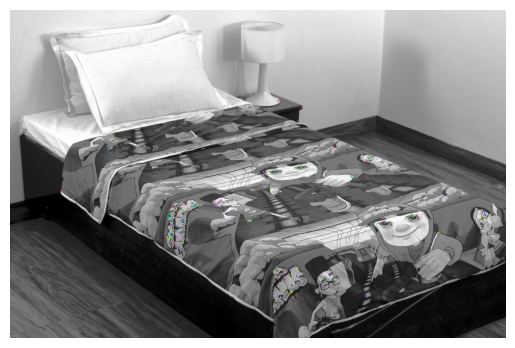

Descripteurs :  (500, 32) 
 [[182  78  64 ... 255 126 134]
 [181  77 131 ... 107 112 186]
 [123 148 103 ... 134 244 253]
 ...
 [216 211  29 ... 128 137  57]
 [ 37 205 123 ... 171  82 168]
 [ 44 187 241 ... 175  70 229]]


In [30]:
# Image d'exemple prétraitée avec conversion en gris et equalisation d'histogramme 
image_ex = img_processed_3

# Conversion en array
img_np = np.array(image_ex)

# Initialisation de l'extracteur
sift = cv2.ORB_create()

# Application de l'extracteur pour obtenir les key points et les descripteurs
kp, des = sift.detectAndCompute(img_np, None)

# Ajout des key point sur l'image 
img=cv2.drawKeypoints(img_np,kp,img_np)

# Construction du plot pour visualiser l'image
plt.imshow(img,  cmap='gray')

# Suppression des axes
plt.axis('off')

# Affichage de l'image
plt.show()

# Affichage de la taille des descripteurs
print("Descripteurs : ", des.shape, "\n", des)

L’application de la méthode ORB sur la même image conduit à l’identification d’un nombre de points clés environ dix fois inférieur à celui obtenu avec SIFT puisqu'ici on remarque que seul 500 descripteurs ont été construits. Cette différence s’explique en partie par le paramétrage par défaut d’ORB, qui limite volontairement le nombre de points détectés pour optimiser la vitesse d’exécution. De plus, on peut voir que la taille des descripteurs générés par ORB est également plus petite avec des vecteurs de dimensions 32, contre 128 pour ceux produits par SIFT. Cette taille de vecteur réduit contribue également à augmenter la vitesse d'execution de l'extraction des descripteurs avec la méthode ORB.

### Application sur l'ensemble des images

Traitement image 0/1050
Traitement image 500/1050
Traitement image 1000/1050

Nombre total de descripteurs : (402044, 32)
Temps d'extraction (ORB) : 3.35 secondes
Nombre de clusters utilisé : 634
temps de traitement du Kmeans:            2.78 secondes
Dimensions avant PCA : (1050, 634)
Dimensions après PCA : (1050, 523)
Adjusted Rand Index (ARI) : 0.0149


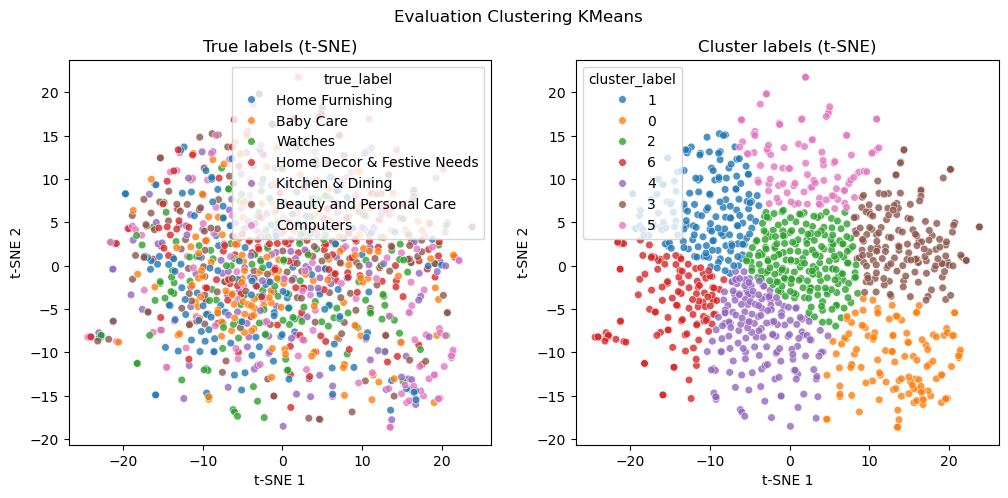

In [31]:
# Défintion du temps de départ
start = time.time()

# Application de tous ces traitements aux images
Data_image.loc[:, 'image_process_ORB'] = process_images(Data_image, 'image_224x224', 
                                             en_gris=True,
                                             filtrage_bruit=False,
                                             egalisation_histo=True,
                                             etirement_histo=False)

# Obtention des descripteurs
descs_list, all_descs = extract_descriptors(Data_image['image_process_ORB'], method='ORB', show_hist=False)

# Entrainement du Kmeans
kmeans_model = train_kmeans(all_descs, n_clusters='auto')

# Construction des features
im_features = build_histograms(kmeans_model, descs_list, show_examples=False)

# Calcul du temps d'extraction des features
duration_ORB = time.time() - start

# Affichage des représentations 2D via TSNE avec catégorie réelles ou prédites
ari_ORB = clustering_and_evaluation(im_features, Data_image, 'ORB', n_clusters=7, verbose=True, title="Evaluation Clustering KMeans")

De nouveau la projection en deux dimensions des features extraites grâce à la méthode ORB ne met en évidence aucune séparation nette entre les catégories de produits. On observe en effet un fort chevauchement entre les différentes catégorie de produits. Cela suggère que les features extraites avec la méthode ORB ne permettent pas de discrimner de facon efficace les catégories des produits de notre jeu de données.

Pour améliorer la séparation des produits, une approche plus avancée va etre explorée.

In [32]:
# Création de la dataframe de résultats
Resultats_ORB = pd.DataFrame({
    'approche': ['ORB'],
    'ari': [ari_ORB],
    "temps d'execution": [duration_ORB]
})

## Extraction de features avec la méthode CNN

Une autre manière d'extraire des caractéristique d'une image est d'utiliser un modèle de réseau de neurones déjà préentrainé pour cela. Un modèle très connu est VGG16, un réseau convolutif profond entrainé sur l'ensemble des données ImageNet qui contient plus de 14 millions d'images réparties en 1000 catégories. A la base le modèle VGG16 permet de prédire la catégorie d'une image mais on peut aussi s'en servir pour extraire des features en récupérant la sortie d'une couche intermédaire. Cette approche correspond à une approche de transfert learning et est souvent utilisées lorsqu'on dispose de peu de données. Afin de mieux comprendre la structure du modèle, sa description est affichée ci dessous.

In [33]:
# Chargement du modèle VGG16
base_model = VGG16()

# Affichage de l'architecture du modèle
Model(inputs=base_model.inputs, outputs=base_model.layers[-1].output).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ fc1 (Dense)                          │ (None, 4096)                │     102,764,544 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

Le modèle VGG16 comporte un total de 22 couches dont 16 sont entrainables. La première couche est une couche d'entrée qui attend des images RGB de taille 224×224 pixels. Cette couche est suivie de 5 blocs convolutifs, chacun constitué de 2 à 3 couches Conv2D suivies d’une couche MaxPooling2D.

Les couches Conv2D permettent d'extraire des motifs visuels locaux (bord, texture, formes) dans l'image en faisant glisser plusieurs filtre 3x3 sur l'image ou sur les map de features issues des couches précédentes. La couche MaxPooling2D va quant a elle récupérer les map de features et réduire leur taille en prenant la valeur maximale dans chaque sous région pour conserver les informations les plus importantes des images.
A la sortie du dernier bloc les cartes de caractéristiques sont de taille (7, 7, 512). 
Ces données sont ensuite aplaties à l’aide d’une couche Flatten, qui transforme la représentation 3D en un vecteur à une dimension pour obtenir des données compatibles avec les couches suivantes qui vont apprendre. Les caractéristiques des images sont alors combinés pour générer une représentation finale par apprentissage des poids sur toutes les entrées. La dernière couche correspond à la couche de classification finale. Elle génères 1000 scores correspondant aux 1000 classes utilisées pour entrainer le modèle.

Ici on ne va pas utiliser la couche de prédiction finale de VGG16. Le modèle servira uniquement comme extracteur de caractéristiques visuelles à partir des images, en récupérant la sortie de la dernière couche dense.

In [34]:
# Suppression de la couche de classification du modèle
model = Model(inputs=base_model.inputs, outputs=base_model.layers[-2].output)

In [35]:
# Définition du temps de départ
start = time.time()

# Initialisation de la liste de features
images_features = []

# Initialisation de la variable de comptage
i = 0

# Pour chaque image
for i, image in enumerate(Data_image['image_224x224']):
    
    # Affichage de la progression toutes les 200 images
    if i % 200 == 0: print(f"Extraction features image {i}")
    
    # Incrémantation de la variable de comptage 
    i += 1
    
    # Conversion de Image PIL en numpy array
    image = img_to_array(image)
    
    # Ajout d'une dimension batch
    image= np.expand_dims(image, axis=0)
    
    # Prétraitement spécifique au modèle
    image = preprocess_input(image)
    
    # Prédiction des features à partir du modèle pré entrainé
    features = model.predict(image, verbose=0)[0]
    
    # Ajout des résultats dans la liste de features
    images_features.append(features)

# Appel de la fonction
images_features = np.asarray(images_features)

# Affichage de la forme de la liste de feature
print('\n Forme liste feature :', images_features.shape)

# Calcul du temps d'extraction des features
duration_CNN = time.time() - start

Extraction features image 0
Extraction features image 200
Extraction features image 400
Extraction features image 600
Extraction features image 800
Extraction features image 1000

 Forme liste feature : (1050, 4096)


Dimensions avant PCA : (1050, 4096)
Dimensions après PCA : (1050, 797)
Adjusted Rand Index (ARI) : 0.4549


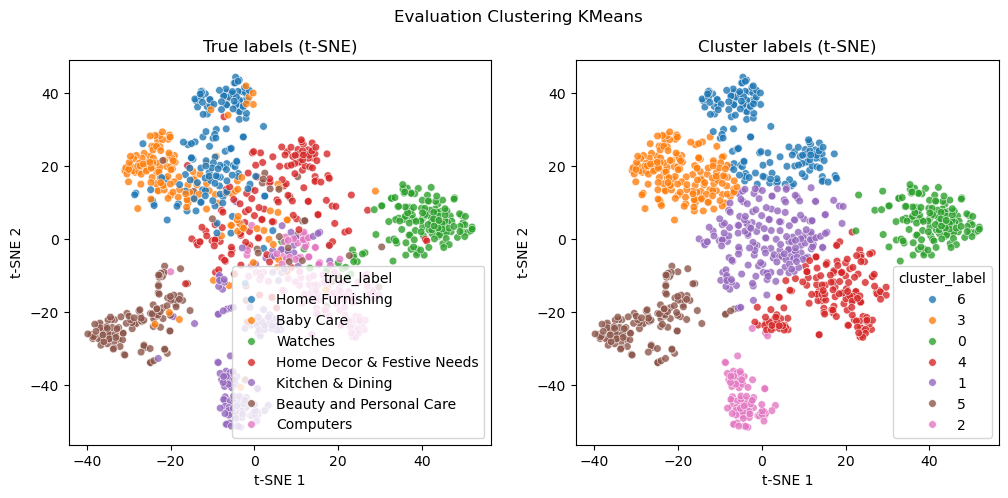

In [36]:
# Affichage des représentations 2D via TSNE avec catégorie réelles ou prédites
ari_CNN = clustering_and_evaluation(images_features, Data_image, 'VGG16', n_clusters=7, verbose=True, title="Evaluation Clustering KMeans")

Lorsque les features sont extraites à partir à partir du modèle VGG16, on remarque une nette amélioration de la séparation des profuits en fonction de leur catégorie. Ce réseau, entraîné sur des millions d’images, apparait donc capable d'extraire des cactéristiques plus spécifiques et plus précises à chaque catégorie. Il permet donc regrouper plus facilement les produits en fonction de leur catégorie. Ces observation permettent de conclure que la classification automatique des produits de la plateforme place de marché à partir des images fournies par les vendeurs apparait parfaitement réalisable. 

In [37]:
# Création de la dataframe de résultats
Resultats_CNN = pd.DataFrame({
    'approche': ['CNN'],
    'ari': [ari_CNN],
    "temps d'execution": [duration_CNN]
})

# Concaténation des résultats
Resultats = pd.concat([Resultats_SIFT, Resultats_ORB, Resultats_CNN])

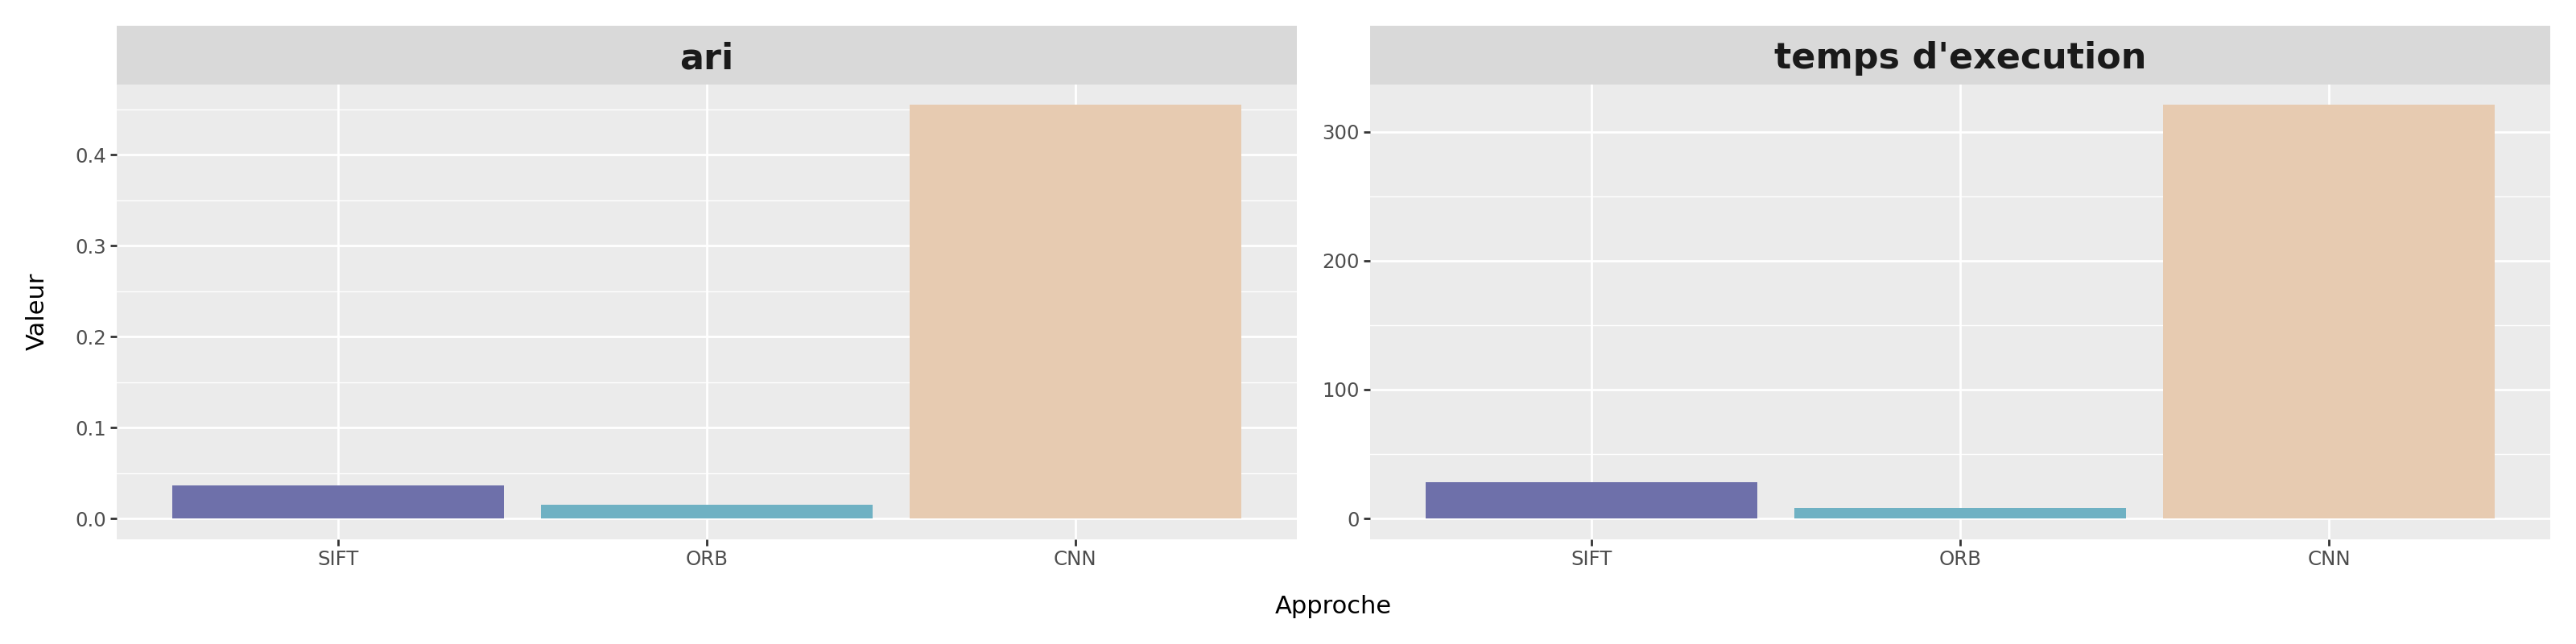

In [38]:
# Reformatage de la table
resultats_pivot = pd.melt(
    Resultats,
    id_vars='approche',
    value_vars=['ari', "temps d'execution"],
    var_name='Score',
    value_name='Value'
)

# Détermination de l'ordre d'apparition des approches
ordre = ['SIFT', 'ORB', 'CNN']

# Conversion de la variable approche en variable catégorielle
resultats_pivot['approche'] = pd.Categorical(resultats_pivot['approche'], categories=ordre, ordered=True)

# Définition d'un dictionnaire de correspondance de couleur
custom_colors = {
    'SIFT': '#6e70aa',  
    'ORB': '#6fb1c3',
    'CNN': '#e7cbb1'}

# Construction du graphique
p = (
    ggplot(resultats_pivot, aes(x='approche', y='Value', fill='approche')) +
    geom_bar(stat='identity', position='dodge') +
    facet_wrap('~ Score', ncol=2, scales='free') +
    scale_fill_manual(values=custom_colors) +
    theme(
        figure_size=(16, 4),
        strip_text=element_text(size=16, weight='bold'),
        legend_position='none'
    ) +
    labs(
        y='Valeur',
        x='Approche'    )
)


# Sauvegarde du graphique
p.save(f"../Output/Extraction_de_features_images/Comparaison_méthodes_d'extraction.png", dpi=300, verbose=False)

# Affichage du graphique
p

Les scores ari confirment ce qui a été observé visuellement sur les graphiques représentant la projection sur un espace bidimensionnel des caractéristiques extraites des images. Pour rappel ces projections ont été obtenues à l’aide d’une réduction de dimension en deux étapes : une PCA conservant 99 % de la variance, suivie d’un t-SNE. On retrouve en effet, un ARI très largement supérieur lorsque les caractéristiques sont extraites par une technique de transfert d'apprentissage qui passe de valeurs inférieures à 0,1 pour les méthodes SIFT et ORB à près de 0,5 pour le transfert d'apprentissage. Le temps d'extraction associé a cette approche est également fortement augmenté mais le gain énorme de performance qui en découle justifie ce cout computationnel.

# Conclusions

L'objectif de cette partie était d'étudier la faisabilité d'une classification de produits de la plateforme place de marché à partir des images fournies par les vendeurs. Cette étude s'est décomposée en plusieurs étapes. Tout d'abord les images ont été prétraitées via différentes approches incluant la conversion en niveau de gris, l'étirement d'histogramme, l'égalisation d'histogramme, ainsi que le fitrage du bruit éventuel (bien qu'à priori les images ne semblaient pas en contenir). L'étape suivante à consister à extraire des caractéristiques des images. Là encore différentes approches ont été employées : (1) des méthodes simples comme SIFT et ORB permettant d'identifier des points clés décrits par des vecteurs descripteurs permettant ensuite d'obtenir des Bag of Visual Word et (2) une approche de transfert learning grâce à l'utilisation d'un modèle de réseau de neurone convolutif pré entrainé permettant d'extraire des features plus riches et plus précises. Pour chacune des approches les caractéristiques des différents produits ont été projeté sur un espace bidimensionnel pour étudier la répartition des produits en fonction de leur groupes.

Les deux premières approches ont aboutit à une mauvaise séparation des produits selon leur caractégories tandis que l'approche de transfert learning à permis d'obtenir un regroupement nettement plus satisfaisant des produits en fonction de leur catégories démontrant la faisabilité d'une classification automatique des produits de la plateforme place de marché à partir des images fournies par les vendeurs.